# 04 The Whispering Gallery

**Series:** Physics of the Integratron (Landers, California)
**Topic T4:** why sound aimed along a curved wall stays close to it and travels round the room.

Notebook 01 dealt with sound that crosses the room and focuses. Notebook 02 found modes that cling to the wall. This notebook looks at that wall-hugging sound in detail. A curved hard wall can carry a whisper round the room in a thin band, with far less loss than sound crossing the room.

1. **Grazing rays.** Sound launched along the wall bounces in short hops and never leaves a band next to it.
2. **Why the whisper stays loud.** Sound in the band spreads over the dome's surface, not through its volume, and refocuses at the opposite wall.
3. **A pulse round the wall.** A simulated whisper travels round the room and comes back after 154 ms.
4. **The wave picture.** Whispering gallery modes, and how thin the band is at each frequency.
5. **What breaks the gallery.** A bump on the wall knocks sound out of the band.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.special import jnp_zeros, jv
from ipywidgets import interact, FloatSlider, IntSlider

SPEED_OF_SOUND = 343.0                   # m/s, air at 20 °C
DOME_RADIUS = 55 * 0.3048 / 2            # 55 ft diameter -> 8.38 m
R = DOME_RADIUS
LAP_S = 2 * np.pi * R / SPEED_OF_SOUND   # once round the wall
SOURCE_GAP = 0.3                         # m, whisperer's mouth to the wall

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
SLIDER_STYLE = {"handle_color": BLUE}  # visible knob on white backgrounds
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "lines.linewidth": 2,
})

print(f"Wall circumference {2 * np.pi * R:.1f} m, one lap takes {LAP_S * 1000:.1f} ms")

Wall circumference 52.7 m, one lap takes 153.5 ms


## 1. Grazing rays stay in a band

Stand with your mouth $h = 0.3$ m from the wall and speak **along** the wall instead of across the room. Treat the sound as a fan of rays, each tilted by up to an angle $\beta$ from the direction along the wall.

Every reflection in a circle obeys one rule. The wall's normal points at the centre, so a reflection cannot change how close the ray's line passes to the centre. That closest distance is the ray's **impact parameter** $b$. A ray that starts with $b$ close to $R$ keeps it forever.

- A ray launched exactly along the wall from distance $h$ has $b = R - h$.
- A ray tilted inward by $\beta$ has $b = (R - h)\cos\beta$.
- No ray in the fan ever gets closer to the centre than $(R - h)\cos\beta$. That circle is the **caustic**, and the sound is trapped in the band between it and the wall.

The left plot shows the fan in the floor plan, going round the room at floor level. The right plot shows the same rays in a vertical slice, going up and over the top of the dome. In the vertical slice, sound that reaches the floor reflects off it, as in notebook 01.

In [2]:
def trace_rays(starts, directions, n_bounces):
    # Follow rays inside a circle of radius R. Returns (n_rays, n_bounces + 1, 2).
    pos = np.array(starts, float)
    direction = np.array(directions, float)
    points = [pos]
    for _ in range(n_bounces):
        b = np.sum(pos * direction, axis=1)
        c = np.sum(pos ** 2, axis=1) - R ** 2
        t = -b + np.sqrt(np.maximum(b ** 2 - c, 0))
        pos = pos + t[:, None] * direction
        points.append(pos)
        normal = pos / R
        direction = direction - 2 * np.sum(direction * normal, axis=1)[:, None] * normal
    return np.stack(points, axis=1)


def launch_fan(half_angle_deg, n_rays):
    # Rays from a source SOURCE_GAP inside the wall, aimed along the wall
    # (counter-clockwise) and tilted by up to half_angle toward or away from the centre
    tilt = np.radians(np.linspace(-half_angle_deg, half_angle_deg, n_rays))
    start = np.array([R - SOURCE_GAP, 0.0])
    directions = np.column_stack([-np.sin(tilt), np.cos(tilt)])
    return np.tile(start, (n_rays, 1)), directions


def caustic_radius(half_angle_deg):
    return (R - SOURCE_GAP) * np.cos(np.radians(half_angle_deg))


def draw_band(ax, inner, upper_only=False):
    phi = np.linspace(0, np.pi if upper_only else 2 * np.pi, 300)
    ring = np.concatenate([R * np.exp(1j * phi), inner * np.exp(1j * phi[::-1])])
    ax.fill(ring.real, ring.imag, color=AQUA, alpha=0.15, linewidth=0)
    ax.plot(inner * np.cos(phi), inner * np.sin(phi), color=ORANGE, linestyle="--",
            linewidth=1.2)
    ax.plot(R * np.cos(phi), R * np.sin(phi), color="k", linewidth=2)


@interact(
    half_angle_deg=FloatSlider(value=10, min=1, max=60, step=1, description="fan ±β (°)",
                               continuous_update=False, style=SLIDER_STYLE),
    n_bounces=IntSlider(value=12, min=1, max=60, description="bounces",
                        continuous_update=False, style=SLIDER_STYLE),
)
def show_grazing_rays(half_angle_deg, n_bounces):
    starts, directions = launch_fan(half_angle_deg, 25)
    paths = trace_rays(starts, directions, n_bounces)
    inner = caustic_radius(half_angle_deg)
    segments = np.concatenate([paths[:, i:i + 2] for i in range(n_bounces)])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.6),
                                   gridspec_kw={"width_ratios": [1, 1.35]})
    draw_band(ax1, inner)
    ax1.add_collection(LineCollection(segments, colors=BLUE, linewidths=0.8, alpha=0.6))
    ax1.scatter(*starts[0], s=70, color=ORANGE, zorder=4)
    ax1.set_aspect("equal")
    ax1.set_xlim(-R * 1.05, R * 1.05)
    ax1.set_ylim(-R * 1.05, R * 1.05)
    ax1.grid(False)
    ax1.set_title("Floor plan: round the room at floor level", fontsize=10)

    folded = segments.copy()
    folded[..., 1] = np.abs(folded[..., 1])
    draw_band(ax2, inner, upper_only=True)
    ax2.plot([-R, R], [0, 0], color="k", linewidth=2)
    ax2.add_collection(LineCollection(folded, colors=BLUE, linewidths=0.8, alpha=0.6))
    ax2.scatter(starts[0, 0], 0, s=70, color=ORANGE, zorder=4)
    ax2.set_aspect("equal")
    ax2.set_xlim(-R * 1.05, R * 1.05)
    ax2.set_ylim(-0.3, R * 1.05)
    ax2.grid(False)
    ax2.set_title("Vertical slice: up and over the dome", fontsize=10)
    fig.suptitle(f"Band from the wall in to the caustic: {R - inner:.2f} m thick "
                 f"(caustic radius {inner:.2f} m)")
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=10.0, continuous_update=False, description='fan ±β (°)', max=60.0, min…

**What the plots show** (defaults: fan ±10°, 12 bounces)

- **Left:** 25 rays from the orange source, seen from above. Every ray stays in the green band between the wall and the orange dashed caustic, which is 0.42 m thick. Each bounce carries a ray 31° to 37° round the room, so 12 bounces take the fan a little over one lap. The middle of the room gets no sound from this fan at all.
- **Right:** the same rays in a vertical slice. They run up the wall, over the top of the dome and down the far side in the same thin band. At the far floor they reflect and come back up.

**Try this:**

- Widen the fan to ±40°. The caustic shrinks to 6.19 m and the band grows to 2.19 m. Sound aimed partly across the room fills much more of it.
- Narrow the fan to ±2° and set 60 bounces. The band is 0.30 m thick, the same as the gap between mouth and wall, and the rays go round about five times without leaving it.
- Move the bounces slider and watch the rays creep round. None of them ever crosses the caustic.

## 2. Why the whisper stays loud

Sound crossing the room spreads in every direction. Its energy is shared over the surface of a growing sphere, so the level falls by 6 dB each time the distance doubles.

Sound in the gallery band is held against the wall. It can only spread **sideways along the wall**, over the dome's surface, so its energy is shared over a growing line instead of a growing sphere.

On a sphere this has a second effect. Each grazing ray stays in a plane through the centre, because every reflection's normal points at the centre. A ray launched along the wall in any direction therefore follows a **great circle**: the largest circle that fits on the sphere. Every great circle through the source also passes through the point directly opposite it. The gallery sound spreads out over the dome and then converges again on the far side of the room.

The top plots show grazing paths from a source on the wall at floor level, seen from above and from the side. The bottom plot compares how fast the level falls with distance along the wall:

- **Across the room (direct):** spreading over a sphere, level $\propto -20\log_{10}(\text{straight-line distance})$.
- **Along the wall (gallery):** spreading along the circle of points the same distance from the source on the dome's surface. That circle has circumference $2\pi R \sin(s/R)$ at distance $s$ along the wall, so level $\propto -10\log_{10}\big(R \sin(s/R)\big)$.

Both curves are set to 0 dB at 1 m. They compare how fast each kind of sound fades, not their absolute levels. The gallery curve applies only to the share of the sound launched close to the wall's direction, and it ignores absorption.

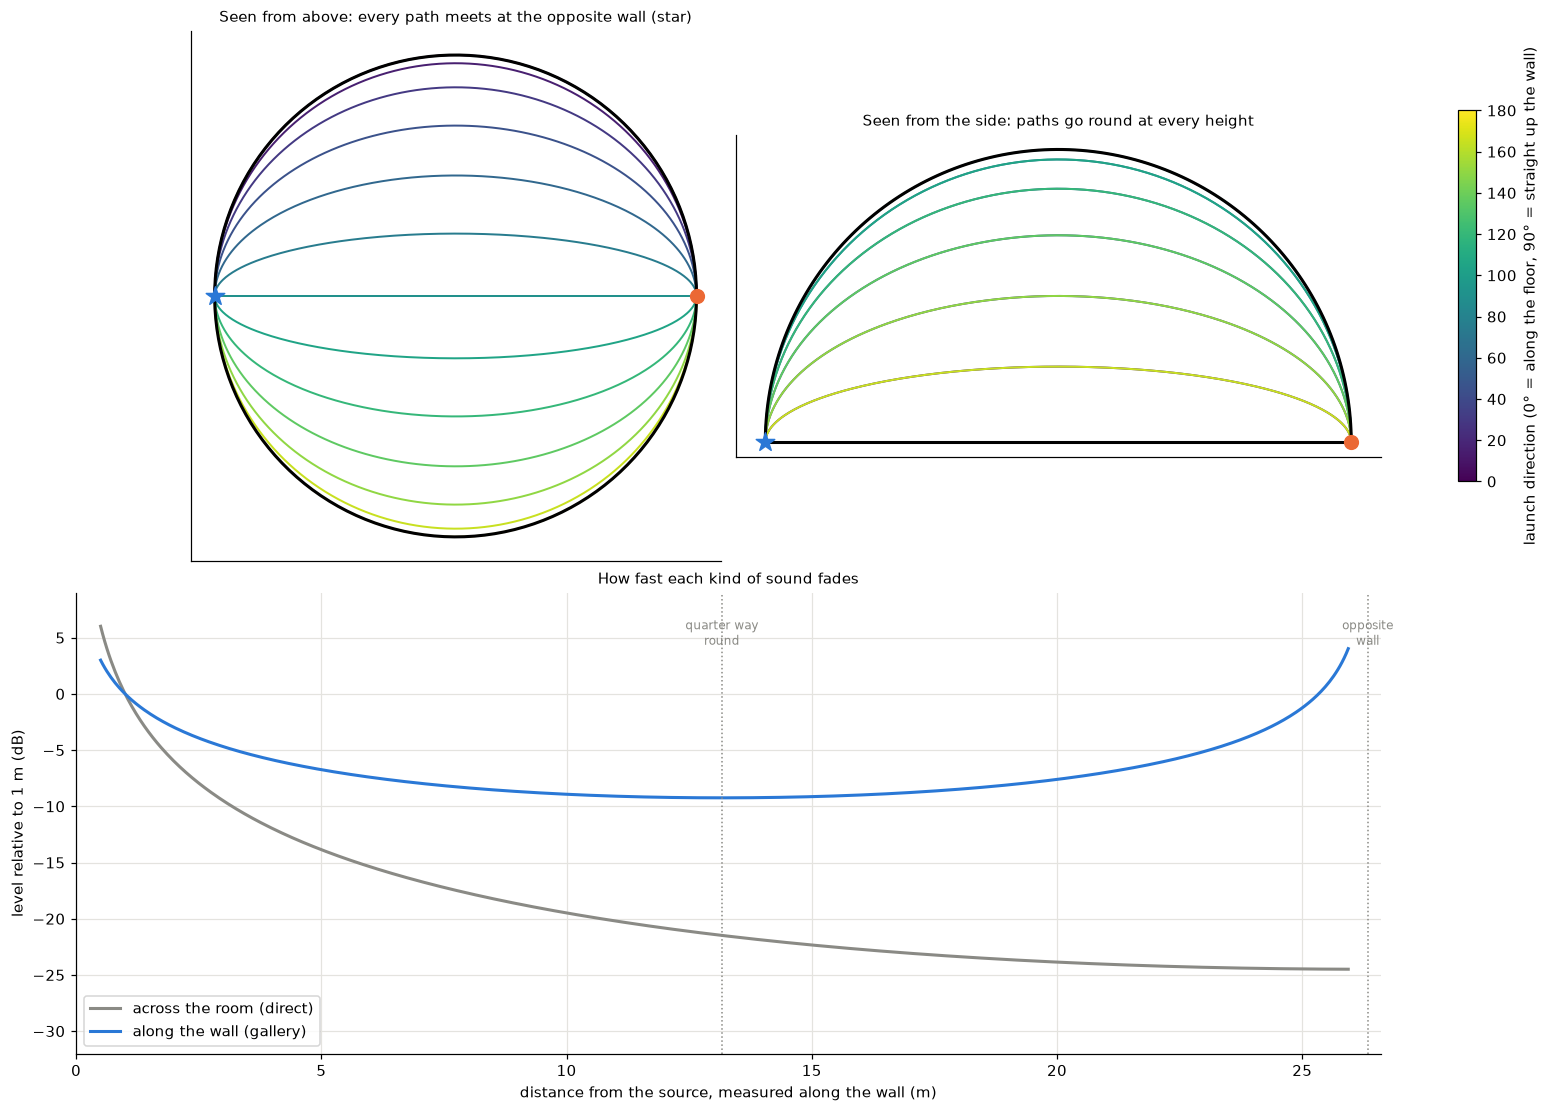

Quarter way round (13.2 m along the wall): direct -21.5 dB, gallery -9.2 dB


In [3]:
fig = plt.figure(figsize=(14, 10), layout="constrained")
grid = fig.add_gridspec(2, 2, height_ratios=[1.15, 1])
ax_top = fig.add_subplot(grid[0, 0])
ax_side = fig.add_subplot(grid[0, 1])
ax_level = fig.add_subplot(grid[1, :])

s = np.linspace(0, np.pi, 300)  # angle travelled round the sphere
for psi_deg in np.arange(0, 181, 15):
    psi = np.radians(psi_deg)
    x = R * np.cos(s)
    y = R * np.sin(s) * np.cos(psi)
    z = R * np.sin(s) * np.sin(psi)
    colour = plt.cm.viridis(psi_deg / 180)
    ax_top.plot(x, y, color=colour, linewidth=1.3)
    ax_side.plot(x, z, color=colour, linewidth=1.3)

phi = np.linspace(0, 2 * np.pi, 300)
ax_top.plot(R * np.cos(phi), R * np.sin(phi), color="k", linewidth=2)
ax_side.plot(R * np.cos(phi[:150]), R * np.sin(phi[:150]), color="k", linewidth=2)
ax_side.plot([-R, R], [0, 0], color="k", linewidth=2)
for ax in (ax_top, ax_side):
    ax.scatter(R, 0, s=80, color=ORANGE, zorder=4)
    ax.scatter(-R, 0, s=160, marker="*", color=BLUE, zorder=4)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
ax_top.set_title("Seen from above: every path meets at the opposite wall (star)",
                 fontsize=10)
ax_side.set_title("Seen from the side: paths go round at every height", fontsize=10)
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(0, 180))
fig.colorbar(sm, ax=[ax_top, ax_side], shrink=0.7,
             label="launch direction (0° = along the floor, 90° = straight up the wall)")

distance = np.linspace(0.5, np.pi * R * 0.985, 600)  # along the wall, m
chord = 2 * R * np.sin(distance / (2 * R))
direct_db = -20 * np.log10(chord / (2 * R * np.sin(1 / (2 * R))))
gallery_db = -10 * np.log10(np.sin(distance / R) / np.sin(1 / R))
ax_level.plot(distance, direct_db, color=GREY, label="across the room (direct)")
ax_level.plot(distance, gallery_db, color=BLUE, label="along the wall (gallery)")
for frac, name in [(0.25, "quarter way\nround"), (0.5, "opposite\nwall")]:
    ax_level.axvline(2 * np.pi * R * frac, color=GREY, linestyle=":", linewidth=1)
    ax_level.text(2 * np.pi * R * frac, 4, name, ha="center", va="bottom", fontsize=8,
                  color=GREY)
ax_level.set_xlim(0, np.pi * R * 1.01)
ax_level.set_ylim(-32, 9)
ax_level.set_xlabel("distance from the source, measured along the wall (m)")
ax_level.set_ylabel("level relative to 1 m (dB)")
ax_level.set_title("How fast each kind of sound fades", fontsize=10)
ax_level.legend(loc="lower left")
plt.show()

quarter = np.argmin(np.abs(distance - np.pi * R / 2))
print(f"Quarter way round ({distance[quarter]:.1f} m along the wall): "
      f"direct {direct_db[quarter]:.1f} dB, gallery {gallery_db[quarter]:.1f} dB")

**What the plots show**

- **Top left:** grazing paths from the orange source seen from above, coloured by launch direction. The purple path runs along the floor-level wall. The teal path goes straight up the wall, over the top and down the far side, so from above it is a straight line. Every path, whatever its direction, ends at the blue star on the opposite wall.
- **Top right:** the same paths from the side. They reach every height on the dome, from the floor (yellow) to the top (teal), and all come down at the star.
- **Bottom:** level against distance along the wall, both set to 0 dB at 1 m. The direct sound (grey) falls quickly, to −21.5 dB a quarter of the way round (13.2 m along the wall). The gallery sound (blue) falls slowly, to −9.2 dB at the same point, 12 dB louder. It is at its weakest there. Beyond that point the paths start converging again, and the gallery level climbs back above 0 dB as it reaches the opposite wall. The direct sound keeps falling, to −24 dB at the opposite wall.

This curve covers only sound launched close to the wall's direction. Sound aimed across the room follows the direct curve. So the gallery effect needs a whisperer who speaks along the wall, and a listener whose ear is near the wall.

## 3. A pulse travelling round the wall

Here the wave equation is solved in the floor plan, using the same simulation as notebook 01 with the source 0.3 m from the wall. A ring of 180 microphones, 0.2 m from the wall, records the pressure all the way round.

This is a 2D simulation, so it shows how sound travels round the wall but not the spreading over the dome from section 2. It takes about ten seconds.

In [4]:
def simulate_ring_pulse(source, duration_s=0.32, dx=0.04, pulse_width=0.12,
                        frame_every_s=0.002, n_probes=180, probe_gap=0.2):
    # Acoustic wave equation on a staggered grid inside a hard circle of radius R.
    # Records frames of the whole floor plan and the pressure on a ring of probes.
    n = int(np.ceil(2 * R / dx)) + 4
    coords = (np.arange(n) - (n - 1) / 2) * dx
    X, Y = np.meshgrid(coords, coords)
    inside = X ** 2 + Y ** 2 < R ** 2
    open_x = inside[:, 1:] & inside[:, :-1]  # faces between two inside cells
    open_y = inside[1:, :] & inside[:-1, :]
    dt = 0.5 * dx / SPEED_OF_SOUND

    p = np.exp(-((X - source[0]) ** 2 + (Y - source[1]) ** 2) / (2 * pulse_width ** 2))
    p *= inside
    vx = np.zeros((n, n - 1))
    vy = np.zeros((n - 1, n))
    div = np.zeros((n, n))

    probe_angles = np.linspace(-np.pi, np.pi, n_probes, endpoint=False)
    probe_r = R - probe_gap
    rows = np.array([np.argmin(np.abs(coords - probe_r * np.sin(a))) for a in probe_angles])
    cols = np.array([np.argmin(np.abs(coords - probe_r * np.cos(a))) for a in probe_angles])

    record_every = 4
    frame_stride = max(1, round(frame_every_s / dt))
    n_steps = int(duration_s / dt)
    frames, frame_times = [p[::2, ::2].astype(np.float32)], [0.0]
    traces, trace_times = [], []
    for step in range(1, n_steps + 1):
        vx -= dt / dx * (p[:, 1:] - p[:, :-1])
        vx *= open_x
        vy -= dt / dx * (p[1:, :] - p[:-1, :])
        vy *= open_y
        div[:] = 0
        div[:, :-1] += vx
        div[:, 1:] -= vx
        div[:-1, :] += vy
        div[1:, :] -= vy
        p -= SPEED_OF_SOUND ** 2 * dt / dx * div
        if step % record_every == 0:
            traces.append(p[rows, cols].copy())
            trace_times.append(step * dt)
        if step % frame_stride == 0:
            frames.append(p[::2, ::2].astype(np.float32))
            frame_times.append(step * dt)
    extent = [coords[0] - dx / 2, coords[-1] + dx / 2] * 2
    return {"frame_times": np.array(frame_times), "frames": np.array(frames),
            "extent": extent, "trace_times": np.array(trace_times),
            "traces": np.array(traces), "probe_angles": probe_angles}


whisper = simulate_ring_pulse((R - SOURCE_GAP, 0.0))
print(f"{len(whisper['frames'])} frames, {whisper['traces'].shape[1]} microphones")

162 frames, 180 microphones


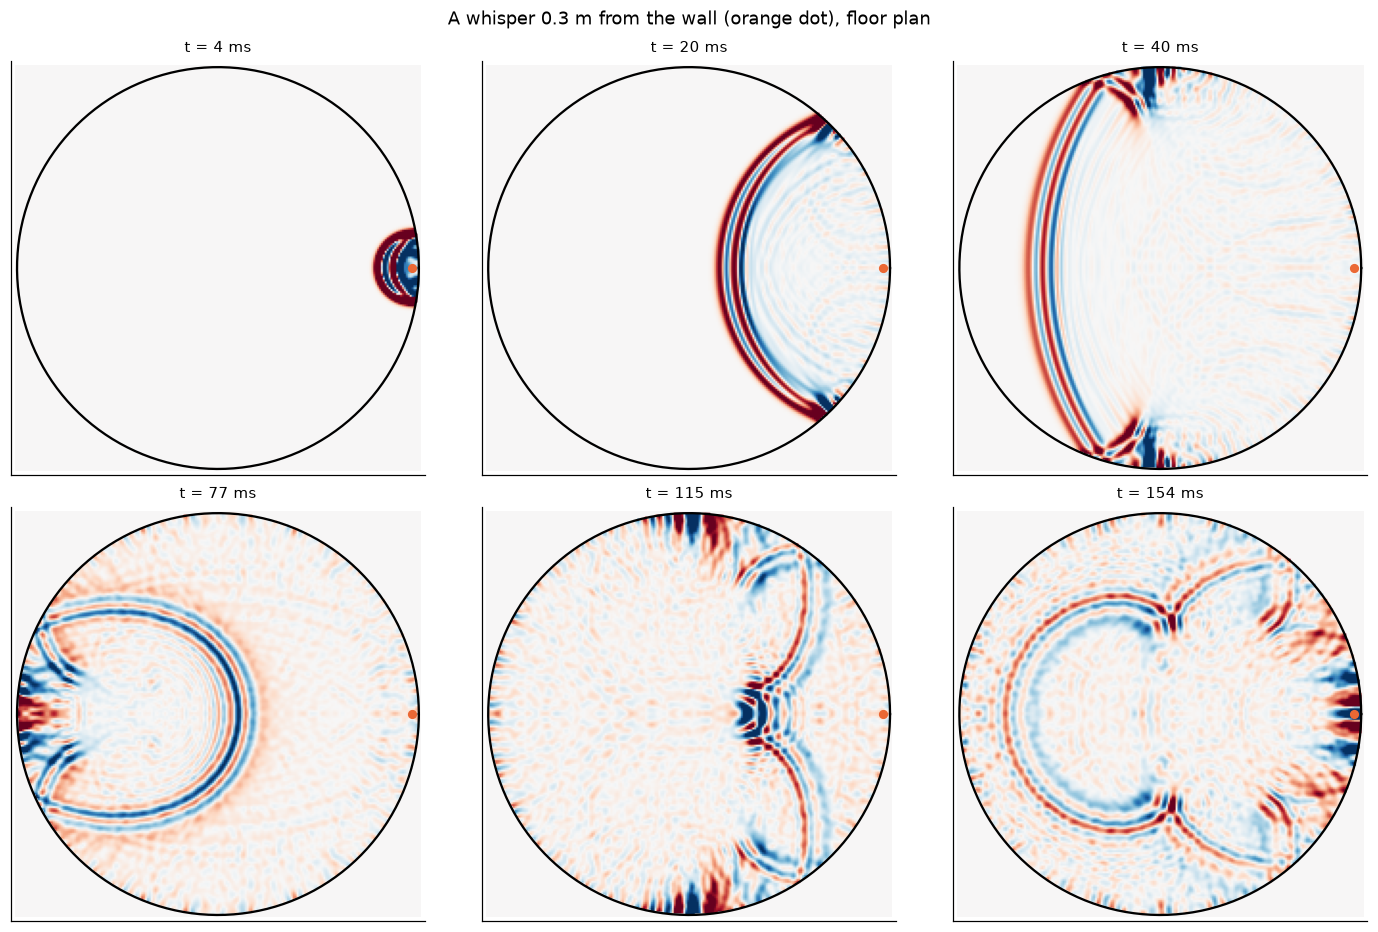

In [5]:
PULSE_VLIM = 0.04  # colour limit; clips the start so the faint later waves show


def draw_ring_frame(ax, frame, extent, title):
    ax.imshow(frame, origin="lower", extent=extent, cmap="RdBu_r",
              vmin=-PULSE_VLIM, vmax=PULSE_VLIM)
    phi = np.linspace(0, 2 * np.pi, 300)
    ax.plot(R * np.cos(phi), R * np.sin(phi), color="k", linewidth=1.5)
    ax.scatter(R - SOURCE_GAP, 0, s=25, color=ORANGE, zorder=4)
    ax.set_aspect("equal")
    ax.set_xlim(-R * 1.03, R * 1.03)
    ax.set_ylim(-R * 1.03, R * 1.03)
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=10)


fig, axes = plt.subplots(2, 3, figsize=(13, 8.6))
for ax, t_ms in zip(axes.flat, [4, 20, 40, 77, 115, 154]):
    i = np.argmin(np.abs(whisper["frame_times"] - t_ms / 1000))
    draw_ring_frame(ax, whisper["frames"][i], whisper["extent"], f"t = {t_ms} ms")
fig.suptitle("A whisper 0.3 m from the wall (orange dot), floor plan")
plt.tight_layout()
plt.show()

**What the figure shows** (red: compression, blue: rarefaction, colour range clipped so faint waves show)

1. **4 ms:** a small ring around the source, already touching the wall.
2. **20 ms:** most of the sound crosses the room as a half ring. Where the ring meets the wall, above and below the source, small dark knots ride along it. These are the gallery waves, one going each way round.
3. **40 ms:** the main ring is about to hit the far wall. The two gallery knots are near the top and bottom of the circle, a quarter of the way round.
4. **77 ms:** the two gallery waves meet at the opposite wall and add up in a bright patch. The main ring has reflected off the far wall and is heading back as a curved front.
5. **115 ms:** the gallery waves are three quarters of the way round, at the top and bottom again, on their way back.
6. **154 ms:** both gallery waves return to the source together. One lap of the 52.7 m wall at the speed of sound takes 153.5 ms.

The speckle filling the room is low-level sound scattered by the simulation's stepped version of the curved wall and by sound crossing the room. It is shown because the colour range is clipped.

### Every microphone at once

The plot below stacks all 180 microphone recordings side by side. Across is the microphone's position round the wall, with the source at 0°. Up is time. Bright means loud. A wave travelling along the wall at the speed of sound shows as a straight diagonal line. The dashed lines mark when sound would arrive if it went along the wall at the speed of sound (green) or straight across the room (white).

Drag the slider to see the room at any moment. The black line on the right marks the same time.

In [6]:
def level_map(sim):
    level = 20 * np.log10(np.abs(sim["traces"]) + 1e-9)
    away = np.abs(sim["probe_angles"]) > np.radians(30)
    return level - np.percentile(level[:, away], 99.9)


WHISPER_LEVEL = level_map(whisper)


def draw_space_time(ax, sim, level):
    angles_deg = np.degrees(sim["probe_angles"])
    t_ms = sim["trace_times"] * 1000
    ax.imshow(level, origin="lower", aspect="auto", cmap="magma", vmin=-40, vmax=0,
              extent=[angles_deg[0], angles_deg[-1] + 2, t_ms[0], t_ms[-1]])
    phi = np.radians(np.linspace(-180, 180, 361))
    along = R * np.abs(phi) / SPEED_OF_SOUND * 1000
    for lap in range(3):
        offset = lap * LAP_S * 1000
        ax.plot(np.degrees(phi), along + offset, color=AQUA, linestyle="--", linewidth=1)
        ax.plot(np.degrees(phi), LAP_S * 1000 - along + offset, color=AQUA,
                linestyle="--", linewidth=1)
    chord = 2 * R * np.abs(np.sin(phi / 2)) / SPEED_OF_SOUND * 1000
    ax.plot(np.degrees(phi), chord, color="w", linestyle="--", linewidth=1)
    ax.set_xlim(-180, 180)
    ax.set_ylim(0, t_ms[-1])
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.set_xlabel("microphone position round the wall (degrees)")
    ax.set_ylabel("time (ms)")
    ax.grid(False)


@interact(
    t_ms=FloatSlider(value=77, min=0, max=318, step=2, description="t (ms)",
                     continuous_update=False, style=SLIDER_STYLE),
)
def show_whisper(t_ms):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.2),
                                   gridspec_kw={"width_ratios": [1, 1.2]})
    i = np.argmin(np.abs(whisper["frame_times"] - t_ms / 1000))
    draw_ring_frame(ax1, whisper["frames"][i], whisper["extent"], f"t = {t_ms:.0f} ms")
    draw_space_time(ax2, whisper, WHISPER_LEVEL)
    ax2.axhline(t_ms, color="w", linewidth=1.5)
    ax2.axhline(t_ms, color="k", linewidth=0.8)
    ax2.set_title("Loudness at every microphone over time (dB)", fontsize=10)
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=77.0, continuous_update=False, description='t (ms)', max=318.0, step=2…

**What the plots show** (default t = 77 ms)

- **Left:** the floor plan at the chosen time, as above.
- **Right:** loudness at all 180 microphones over 320 ms. The black area at the bottom is before any sound arrives. Its upper edge follows the white dashed curve, the straight path across the room, which reaches the far side at 49 ms.
- The bright **X** pattern is the gallery. Two lines leave the source at 0° and run outward along the green dashed lines, the speed of sound along the wall. They cross at the opposite wall (±180°) at 77 ms and back at the source at 154 ms. They do it again at 230 ms and 307 ms. The whisper goes round the room twice and is still the loudest thing in the plot.

Measured from the microphones:

| Position round the wall | Direct sound arrives | Gallery arrives | Gallery louder by |
|---|---|---|---|
| 90° | 34.6 ms | 38.4 ms | 7.6 dB |
| 135° | 45.2 ms | 57.6 ms | 9.9 dB |
| 180° | 48.9 ms | 76.8 ms | 13.9 dB |

At 180° the gallery waves from both directions arrive together, which adds to the gain. Back at the source, the gallery pulse after two laps is 2.3 dB weaker than after one. Some of that is the pulse spreading out and some is scattering from the stepped wall in the simulation.

**Try this:**

- Step to 20 ms. The knots at the wall are just starting out.
- Step to 154 ms. Both gallery waves are back at the source.
- Step to 300 ms. The room is full of scattered sound, but the bright knots near the source are the whisper finishing its second lap.

### Hear the whisper go round

The cell below runs the same simulation for 1 s, about six and a half laps, and plays three of the microphones:

- **next to the source (0°):** the first 10 ms, the whisper itself, is removed so the returns can be heard.
- **a quarter of the way round (90°).**
- **the opposite wall (180°).**

The 90° and 180° players use the same volume setting. The simulated pulse holds little sound above 1 kHz, so it plays as a soft thump. The run takes about 15 s.

In [ ]:
from IPython.display import Audio, display
from scipy.signal import resample_poly

AUDIO_RATE = 22050
long_whisper = simulate_ring_pulse((R - SOURCE_GAP, 0.0), duration_s=1.0, frame_every_s=10.0)
# Microphones are recorded 4287.5 times a second: resample to a standard audio rate
picks = {"next to the source (0°)": 0.0, "a quarter of the way round (90°)": np.pi / 2,
         "opposite wall (180°)": np.pi}
recordings = {}
for name, angle in picks.items():
    j = np.argmin(np.abs(np.angle(np.exp(1j * (long_whisper["probe_angles"] - angle)))))
    recordings[name] = resample_poly(long_whisper["traces"][:, j], 36, 7)
recordings["next to the source (0°)"][:int(0.01 * AUDIO_RATE)] = 0
shared = 0.9 / max(np.abs(recordings[name]).max() for name in list(picks)[1:])
volumes = {name: shared for name in list(picks)[1:]}
volumes["next to the source (0°)"] = 0.9 / np.abs(recordings["next to the source (0°)"]).max()

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, (name, recording), colour in zip(axes, recordings.items(), [ORANGE, BLUE, AQUA]):
    t_ms = np.arange(len(recording)) / AUDIO_RATE * 1000
    ax.plot(t_ms, recording * volumes[name], color=colour, linewidth=0.7)
    start = {0.0: 0.0, np.pi / 2: 0.25, np.pi: 0.5}[picks[name]] * LAP_S * 1000
    for lap in range(8):
        for arrival in (start + lap * LAP_S * 1000, (lap + 1) * LAP_S * 1000 - start):
            ax.axvline(arrival, color=GREY, linestyle=":", linewidth=0.8)
    ax.set_ylim(-1, 1)
    ax.set_ylabel("pressure")
    ax.set_title(name, fontsize=10, loc="left", color=colour)
axes[-1].set_xlim(0, 1000)
axes[-1].set_xlabel("time (ms), dotted lines: gallery arrivals going each way round")
plt.tight_layout()
plt.show()
for name, recording in recordings.items():
    print(name)
    display(Audio(recording * volumes[name], rate=AUDIO_RATE, normalize=False))

**What the plots show** (dotted lines: when a gallery wave should arrive, going either way round the wall)

- **Next to the source:** the whisper comes back at 154 ms and 307 ms as sharp swings, with both gallery waves arriving together after one lap and after two. The third and fourth laps, at 460 ms and 614 ms, still show but sink into a growing background.
- **A quarter of the way round:** the first gallery wave arrives at 38 ms, just behind the direct sound at 35 ms. The wave going the long way round arrives at 115 ms. These arrivals are smaller than at the opposite wall.
- **The opposite wall:** a large arrival at 77 ms, where the two gallery waves meet, then more at 230, 384 and 537 ms, every 154 ms and getting smaller.

The background grows over the second because the simulated walls absorb nothing. Sound scattered by the stepped wall and sound crossing the room keep adding up. A real room absorbs some of it.

In the players, next to the source and at the opposite wall you hear a thump repeating about 6.5 times a second, sinking into a rumble.

## 4. The wave picture: whispering gallery modes

Notebook 02 found 3D modes with $l = m$ that hug the wall. The floor plan has the same kind of mode in 2D:

$$p(r, \phi) = J_m(k r)\, \cos(m\phi)$$

- $J_m$ is a **Bessel function**. It is close to zero from the centre out to about $r = m/k$, then rises to its peak at the wall.
- $\cos(m\phi)$ gives $2m$ lobes round the wall.
- The hard wall sets $k R$ to a zero of $J_m'$. The first zero gives the mode that hugs the wall most tightly.

The silent region inside $r = m/k$ is the wave version of the caustic from section 1. For large $m$ the band between it and the wall is about

$$R - \frac{m}{k} \approx 0.81\, R\, m^{-2/3}$$

so the band gets thinner as the frequency rises. The gallery below shows six modes on the floor plan.

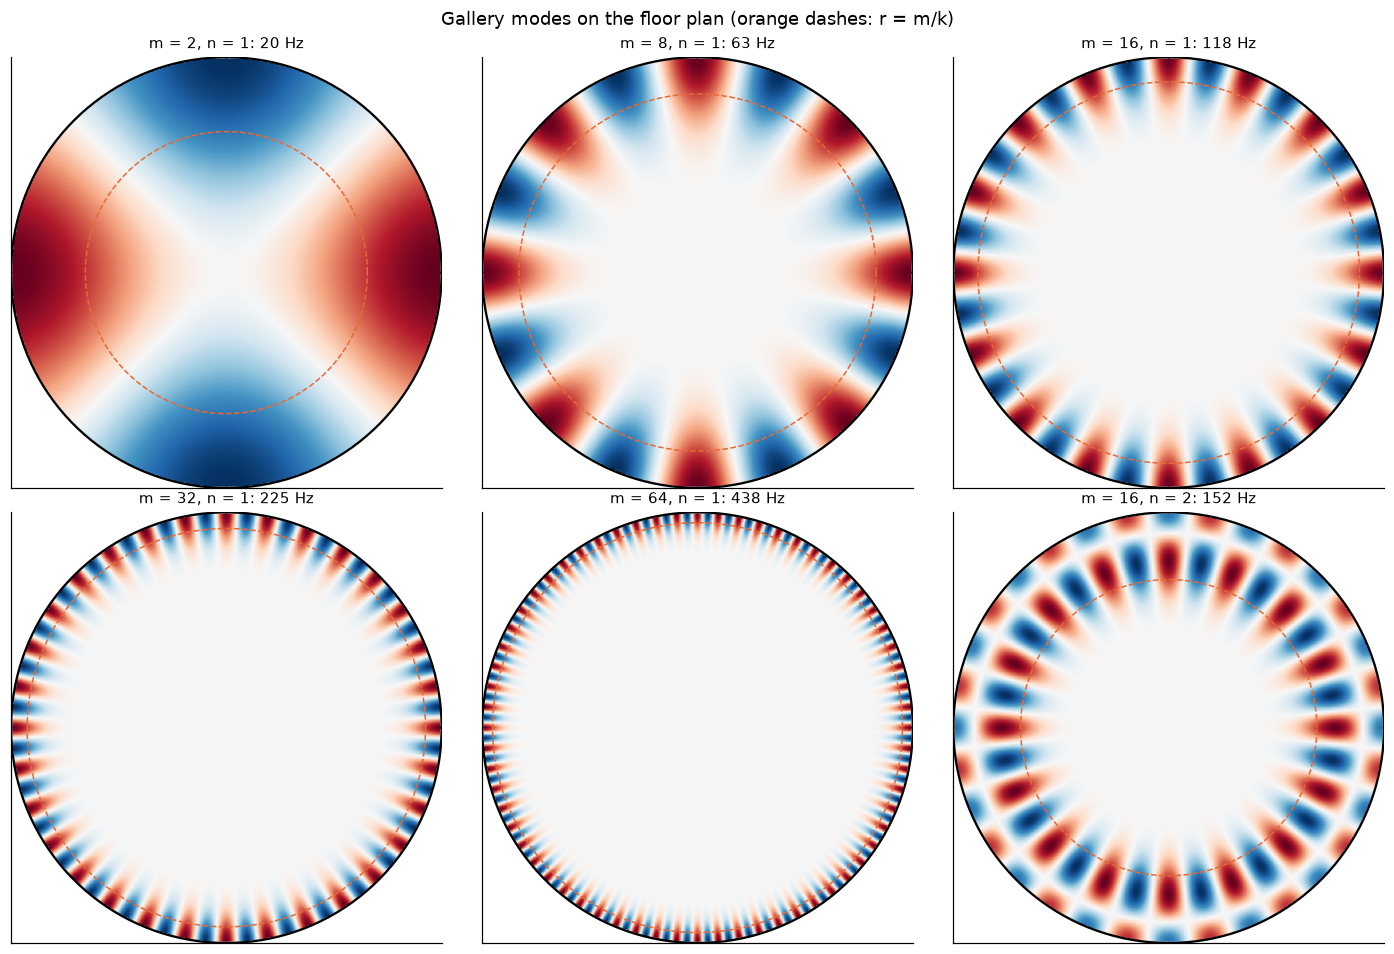

In [7]:
def gallery_kr(m, n=1):
    return jnp_zeros(m, n)[n - 1]


def gallery_frequency(m, n=1):
    return gallery_kr(m, n) * SPEED_OF_SOUND / (2 * np.pi * R)


PLAN_X, PLAN_Y = np.meshgrid(np.linspace(-R, R, 321), np.linspace(-R, R, 321))
PLAN_R = np.hypot(PLAN_X, PLAN_Y)
PLAN_PHI = np.arctan2(PLAN_Y, PLAN_X)


def draw_gallery_mode(ax, m, n):
    k = gallery_kr(m, n) / R
    p = jv(m, k * PLAN_R) * np.cos(m * PLAN_PHI)
    p = np.where(PLAN_R <= R, p, np.nan)
    p /= np.nanmax(np.abs(p))
    ax.imshow(p, origin="lower", extent=[-R, R, -R, R], cmap="RdBu_r", vmin=-1, vmax=1)
    phi = np.linspace(0, 2 * np.pi, 300)
    ax.plot(R * np.cos(phi), R * np.sin(phi), color="k", linewidth=1.5)
    if m > 0:
        ax.plot(m / k * np.cos(phi), m / k * np.sin(phi), color=ORANGE, linestyle="--",
                linewidth=1)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])


fig, axes = plt.subplots(2, 3, figsize=(13, 8.8))
for ax, (m, n) in zip(axes.flat, [(2, 1), (8, 1), (16, 1), (32, 1), (64, 1), (16, 2)]):
    draw_gallery_mode(ax, m, n)
    ax.set_title(f"m = {m}, n = {n}: {gallery_frequency(m, n):.0f} Hz", fontsize=10)
fig.suptitle("Gallery modes on the floor plan (orange dashes: r = m/k)")
plt.tight_layout()
plt.show()

**What the figure shows**

Each panel is the floor plan of one mode. Red and blue are opposite pressures and white is silent. The orange dashed circle is $r = m/k$.

- **m = 2 (20 Hz):** four broad lobes that fill most of the room. With so few lobes there is no thin band yet.
- **m = 8 (63 Hz), m = 16 (118 Hz), m = 32 (225 Hz), m = 64 (438 Hz):** the lobes multiply and squeeze into a thinner and thinner ring against the wall. Inside the dashed circle the room is silent. At m = 64 the ring is a narrow strip.
- **m = 16, n = 2 (152 Hz):** a second ring of lobes inside the first. Higher $n$ uses more of the space between the caustic and the wall.

The m = 16 mode here is at 117.6 Hz. In notebook 02 the 3D mode with $l = m = 16$, which runs round the floor-level wall, is at 120.2 Hz. They are the same kind of wave, in 2D and 3D.

### How thin is the band?

For each mode with $n = 1$, the plot measures how far in from the wall the loudness falls to half its value at the wall. That is the thickness of the band where the whisper lives.

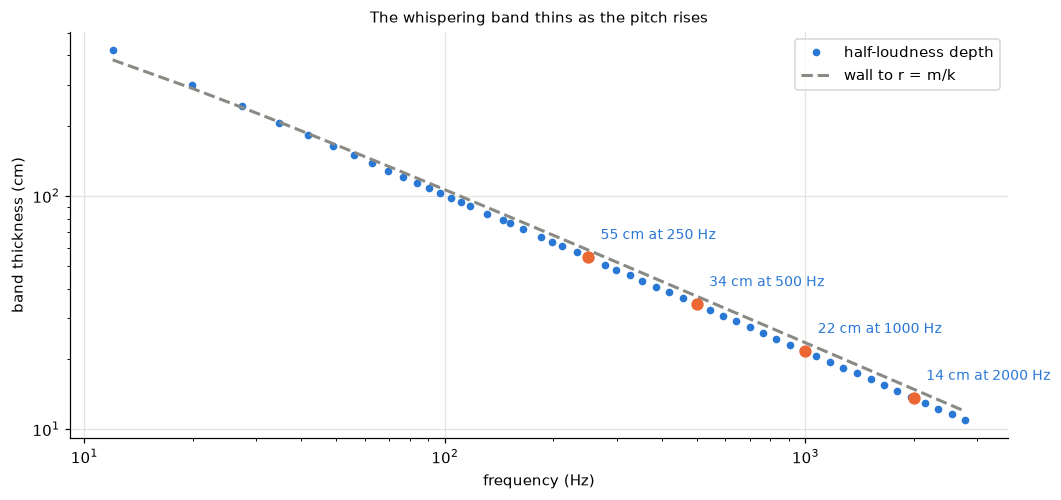

2D mode m=16, n=1: 117.6 Hz


In [8]:
m_values = np.unique(np.round(np.logspace(0, np.log10(420), 70)).astype(int))
band_freq, band_half, band_caustic = [], [], []
depth = np.linspace(0, 0.6, 6001)  # fraction of R in from the wall
for m in m_values:
    kr = gallery_kr(m)
    loudness = jv(m, kr * (1 - depth)) ** 2
    below = np.flatnonzero(loudness < loudness[0] / 2)
    band_freq.append(gallery_frequency(m))
    band_half.append(depth[below[0]] * R)
    band_caustic.append(R * (1 - m / kr))
band_freq, band_half, band_caustic = map(np.array, (band_freq, band_half, band_caustic))

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(band_freq, band_half * 100, "o", color=BLUE, markersize=4,
        label="half-loudness depth")
ax.plot(band_freq, band_caustic * 100, color=GREY, linestyle="--",
        label="wall to r = m/k")
for f in (250, 500, 1000, 2000):
    depth_cm = np.interp(f, band_freq, band_half) * 100
    ax.annotate(f"{depth_cm:.0f} cm at {f} Hz", (f, depth_cm), xytext=(8, 12),
                textcoords="offset points", fontsize=9, color=BLUE)
    ax.scatter([f], [depth_cm], s=50, color=ORANGE, zorder=4)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("band thickness (cm)")
ax.set_title("The whispering band thins as the pitch rises", fontsize=10)
ax.legend()
plt.show()
print(f"2D mode m=16, n=1: {gallery_frequency(16):.1f} Hz")

**What the plot shows**

Both axes are logarithmic, so a straight line means a power law. The blue dots are the depth where the mode's loudness falls to half its value at the wall. They fall on a straight line just under the grey line from the wall to $r = m/k$, which slopes as $f^{-2/3}$.

- 250 Hz: 55 cm thick
- 500 Hz: 34 cm
- 1000 Hz: 22 cm
- 2000 Hz: 14 cm

Each doubling of frequency thins the band by about 37%. At 2 kHz, where much of a whisper's sound lies, the band is 14 cm deep, so a listener's ear must be within about that distance of the wall to be inside it.

### Mode explorer

Pick a mode. The left panel is the floor plan. The right panel is a slice from the centre to the wall, with the band between $r = m/k$ and the wall shaded.

In [9]:
@interact(
    m=IntSlider(value=24, min=0, max=80, description="m", continuous_update=False,
                style=SLIDER_STYLE),
    n=IntSlider(value=1, min=1, max=4, description="n", continuous_update=False,
                style=SLIDER_STYLE),
)
def show_gallery_mode(m, n):
    k = gallery_kr(m, n) / R
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5),
                                   gridspec_kw={"width_ratios": [1, 1.4]})
    draw_gallery_mode(ax1, m, n)
    ax1.set_title(f"m = {m}, n = {n}: {gallery_frequency(m, n):.0f} Hz", fontsize=10)

    r = np.linspace(0, R, 2000)
    loudness = jv(m, k * r) ** 2
    ax2.plot(r, loudness / loudness.max(), color=BLUE)
    if m > 0:
        ax2.axvspan(m / k, R, color=AQUA, alpha=0.15, label="r = m/k to the wall")
        ax2.axvline(m / k, color=ORANGE, linestyle="--", linewidth=1)
        ax2.legend(loc="upper left", fontsize=8)
    ax2.axvline(R, color="k", linewidth=2)
    ax2.set_xlim(0, R * 1.02)
    ax2.set_xlabel("distance from the centre (m)")
    ax2.set_ylabel("loudness (peak = 1)")
    ax2.set_title("Loudness from the centre out to the wall", fontsize=10)
    plt.tight_layout()
    plt.show()

interactive(children=(IntSlider(value=24, continuous_update=False, description='m', max=80, style=SliderStyle(…

**What the plots show** (default m = 24, n = 1, 172 Hz)

- **Left:** 48 lobes round the wall and a silent centre.
- **Right:** loudness from the centre to the wall. It is zero out to about 6 m, rises steeply, and peaks right at the wall. The shaded band, from $r = m/k$ (7.6 m) to the wall, holds almost all of it.

**Try this:**

- Set m = 4. The lobes reach far into the room. This is no longer a whisper band.
- Set m = 80. The loudness is a spike against the wall.
- Set m = 24 and n = 3 (238 Hz). Three rings of lobes, and the shaded band widens to start at 5.5 m. The ring nearest the caustic is the loudest.

## 5. What breaks the gallery

Everything so far assumes a perfectly smooth wall. A real wall has joints, ribs, window openings, and people sitting against it. This notebook does not model any specific feature of the Integratron. It asks a general question: what does one bump on the wall do to the band?

The model puts a round bump, sticking out $a$ metres from the wall, a quarter of the way round from the source. Rays reflect off the bump's curved face as well as the wall. The plot follows each ray for one lap of the room.

- **Blue** rays finish the lap still inside the original band.
- **Orange** rays were knocked out of the band or sent backwards.

Rays are a fair picture only when the bump is larger than the wavelength. A bump much smaller than the wavelength barely disturbs the wave. Section 4 showed that low notes also use a thicker band, so low notes pass small bumps and high notes are the ones that get scattered.

In [10]:
BUMP_ANGLE = np.pi / 2  # a quarter of the way round from the source


def trace_one_lap(half_angle_deg, bump_size, n_rays=60, max_bounces=300, keep_paths=True):
    # Follow each ray for one lap, reflecting off the wall and a round bump of radius
    # bump_size centred on the wall. Returns paths and whether each ray kept its band.
    starts, directions = launch_fan(half_angle_deg, n_rays)
    band_inner = caustic_radius(half_angle_deg)
    centre = R * np.array([np.cos(BUMP_ANGLE), np.sin(BUMP_ANGLE)])
    pos, d = starts.copy(), directions.copy()
    swept = np.zeros(n_rays)
    done = np.zeros(n_rays, bool)
    paths = [[p.copy()] for p in pos]
    for _ in range(max_bounces):
        active = np.flatnonzero(~done)
        if active.size == 0:
            break
        p, dd = pos[active], d[active]
        b = np.sum(p * dd, axis=1)
        c = np.sum(p ** 2, axis=1) - R ** 2
        t_wall = -b + np.sqrt(np.maximum(b ** 2 - c, 0))
        t_bump = np.full(active.size, np.inf)
        if bump_size > 0:
            f = p - centre
            fb = np.sum(f * dd, axis=1)
            fc = np.sum(f * f, axis=1) - bump_size ** 2
            disc = fb ** 2 - fc
            hit = (disc > 0) & (fc > -1e-9)
            t_hit = -fb - np.sqrt(np.maximum(disc, 0))
            # Only the half of the bump inside the room counts
            q = p + np.nan_to_num(t_hit)[:, None] * dd
            inside_room = np.sum(q ** 2, axis=1) <= R ** 2 + 1e-9
            t_bump = np.where(hit & (t_hit > 1e-9) & inside_room, t_hit, np.inf)
        on_bump = t_bump < t_wall
        t = np.where(on_bump, t_bump, t_wall)
        new = p + t[:, None] * dd
        normal = np.where(on_bump[:, None], new - centre, new)
        normal /= np.linalg.norm(normal, axis=1)[:, None]
        dd = dd - 2 * np.sum(dd * normal, axis=1)[:, None] * normal
        d[active] = dd / np.linalg.norm(dd, axis=1)[:, None]
        step = np.angle((new[:, 0] + 1j * new[:, 1]) / (p[:, 0] + 1j * p[:, 1]))
        swept[active] += step
        pos[active] = new
        if keep_paths:
            for i, q in zip(active, new):
                paths[i].append(q.copy())
        done[active] = np.abs(swept[active]) >= 2 * np.pi
    impact = np.abs(pos[:, 0] * d[:, 1] - pos[:, 1] * d[:, 0])
    kept = (swept >= 2 * np.pi) & (impact >= band_inner - 1e-6)
    return paths, kept


BUMP_SIZES = np.linspace(0, 0.8, 33)


@interact(
    bump_size=FloatSlider(value=0.2, min=0.0, max=0.8, step=0.05, description="bump a (m)",
                          continuous_update=False, style=SLIDER_STYLE),
    half_angle_deg=FloatSlider(value=10, min=2, max=30, step=1, description="fan ±β (°)",
                               continuous_update=False, style=SLIDER_STYLE),
)
def show_bump(bump_size, half_angle_deg):
    paths, kept = trace_one_lap(half_angle_deg, bump_size)
    curve = [trace_one_lap(half_angle_deg, a, keep_paths=False)[1].mean()
             for a in BUMP_SIZES]
    band = R - caustic_radius(half_angle_deg)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.8),
                                   gridspec_kw={"width_ratios": [1, 1.2]})
    draw_band(ax1, caustic_radius(half_angle_deg))
    for path, ok in zip(paths, kept):
        path = np.array(path)
        ax1.plot(path[:, 0], path[:, 1], color=BLUE if ok else ORANGE,
                 linewidth=0.7, alpha=0.7 if ok else 0.9)
    if bump_size > 0:
        bump = plt.Circle((R * np.cos(BUMP_ANGLE), R * np.sin(BUMP_ANGLE)), bump_size,
                          color="k", zorder=4)
        ax1.add_patch(bump)
    ax1.scatter(R - SOURCE_GAP, 0, s=70, color=ORANGE, zorder=5)
    ax1.set_aspect("equal")
    ax1.set_xlim(-R * 1.05, R * 1.05)
    ax1.set_ylim(-R * 1.05, R * 1.05)
    ax1.grid(False)
    ax1.set_title(f"One lap with a {bump_size:.2f} m bump: {kept.mean():.0%} of rays "
                  "stay in the band", fontsize=10)

    ax2.plot(BUMP_SIZES, np.array(curve) * 100, "o-", color=BLUE, markersize=4)
    ax2.scatter([bump_size], [kept.mean() * 100], s=90, color=ORANGE, zorder=4)
    ax2.axvline(band, color=AQUA, linestyle="--", linewidth=1.2)
    ax2.text(band, 5, f"  band thickness {band:.2f} m", color=AQUA)
    ax2.set_ylim(-3, 103)
    ax2.set_xlabel("bump size a (m)")
    ax2.set_ylabel("rays still in the band after one lap (%)")
    ax2.set_title("Bigger bumps knock more sound out of the band", fontsize=10)
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=0.2, continuous_update=False, description='bump a (m)', max=0.8, step=…

**What the plots show** (defaults: bump a = 0.2 m, fan ±10°)

- **Left:** the black dot at the top is the bump. Blue rays went round the room and are still in the 0.42 m band. Orange rays hit the bump at a steep angle and were thrown across the room in long chords. With a 0.2 m bump, 82% of the rays stay in the band.
- **Right:** the share of rays that stay in the band after one lap, for bumps from 0 to 0.8 m. It falls gradually at first: 95% at 0.05 m, 82% at 0.2 m, 50% at 0.3 m. Then it collapses to almost nothing once the bump reaches about 0.35 m, close to the band's full thickness (green line).

**Try this:**

- Set the bump to 0.05 m. A few rays clip it and are thrown across the room, but 95% stay in the band.
- Set the bump to 0.6 m. It blocks the band completely, and every ray is sent off on a different path.
- Widen the fan to ±25°. The band is now 1.06 m thick. The share falls more slowly with bump size and is still about 15% at 0.8 m, because a wider band has room for rays to pass the bump.

A 0.2 m bump is one wavelength across at 1.7 kHz. The ray result applies above roughly that frequency. Lower notes are long compared to the bump and pass it with little scattering, and they also use a deeper band.

## Summary

| Idea | Formula | Integratron scale |
|---|---|---|
| Ray band | inner edge $b = (R - h)\cos\beta$ | 0.42 m thick for $h$ = 0.3 m, $\beta$ = 10° |
| One lap | $2\pi R / c$ | 52.7 m in 154 ms |
| Spreading along the wall | level $\propto -10\log_{10}\!\big(R\sin(s/R)\big)$ | 12 dB above direct sound a quarter way round |
| Refocusing | every great circle meets the opposite point | opposite wall, 77 ms after the whisper |
| Band thickness (modes) | $R - m/k \approx 0.81\,R\,m^{-2/3}$ | 34 cm at 500 Hz, 14 cm at 2 kHz |
| 2D and 3D gallery modes | $J_m(kr)\cos m\phi$ and $l = m$ | 117.6 Hz and 120.2 Hz for $m = 16$ |
| One bump | ray model, valid above $f \approx c/a$ | a 0.2 m bump knocks 18% of the band out per lap |

1. A reflection in a curved wall cannot change how close a ray passes to the centre. Sound launched along the wall stays in a band next to it.
2. In the band, sound spreads over the dome's surface instead of through the room. A quarter of the way round it is about 12 dB louder than sound crossing the room.
3. On a sphere every grazing path is a great circle, so the gallery sound refocuses on the wall directly opposite the source.
4. A whisper goes round the 52.7 m wall in 154 ms and can complete more than one lap.
5. The band is the region between the wall and $r = m/k$. It thins as the pitch rises, from 55 cm at 250 Hz to 14 cm at 2 kHz.
6. Anything sticking out from the wall by a good fraction of the band's thickness scatters the gallery sound into the room. Small features matter only at high frequencies.

**Next:** [05 The Singing Bowl](05_singing_bowl.ipynb): the physics of the instrument most often played in the dome, and how its notes meet the room.